# 03b · Tuning round (Tier A)

**Purpose.** Notebook 03 left several settings as untuned judgment calls, most importantly the strength of the chosen logistic regression. Its result (+2.9 hits per 100 visits over Rule 1) fell just short of the +3 bar. This notebook tunes the four highest-value judgment calls (agreed scope: **Tier A** in `PLAN.md`) and re-judges the exit criterion (§1–§7). It then runs a **two-week replay** with the adopted model (§8), to check how much the results rely on the within-month stability assumption.

| Step | Setting | Values tried | Current (notebook 03) |
|---|---|---|---|
| A1 | Logistic-regression strength and penalty | C ∈ {0.001 … 10}; L2 and L1 | C = 0.1, L2 |
| A2 | Local-strictness radius and windows | 0.5 / 1 / 2 km × 90 / 180 / 365 days | 1 km; 90 + 180 days |
| A3 | Recency weight (EWMA) and "last N routine visits" | α ∈ {0.2, 0.35, 0.5, 0.7} × N ∈ {2, 3, 5} | α = 0.5, N = 3 |
| A4 | Drop the weak feature groups | 311 nearby, owner, violation mix, calendar & place | all kept |

**Guardrails (agreed before running)**
- **Selection uses folds 1–2 only** (predicting 2022 and 2023 from earlier years). Each setting is scored by mean PR-AUC over those two folds, a smooth ranking measure, with the first-half hit rate shown alongside.
- **Sequential, not a grid:** A1 → A4, each step keeping the previous step's winner. About 35 configurations in total.
- **A4 drop rule (fixed in advance):** a group is dropped if removing it costs less than **0.002 PR-AUC**, the spread between the top tuning configurations in notebook 03, i.e. within noise. Simpler wins ties.
- **Exit verdict on 2024 alone.** 2024 was never used for any selection here, so it is the clean check: the tuned model must beat Rule 1 by ≥ 3 hits per 100 visits with a 95% CI excluding zero. The pooled 2022–24 result is shown for continuity but is slightly flattered, because 2022–23 picked the settings.
- The test period stays locked: no test-period row is built.

## 0 · Setup

In [1]:
import re
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.neighbors import BallTree
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from inspections import config

pd.set_option('display.width', 160)
EARTH_RADIUS_M = 6_371_000
SELECTION_FOLDS = [2022, 2023]
ALL_FOLDS = [2022, 2023, 2024]
NOISE = 0.002

visits = pd.read_parquet(config.PROCESSED / 'visits.parquet')
violations = pd.read_parquet(config.PROCESSED / 'violations.parquet')
licenses = pd.read_parquet(config.PROCESSED / 'licenses.parquet')
complaints = pd.read_parquet(config.PROCESSED / 'complaints.parquet')
print(f'{len(visits):,} visits · {len(violations):,} violations · {len(complaints):,} 311 cases')

193,852 visits · 835,847 violations · 67,320 311 cases


**Carried over from notebook 03, unchanged:** the metric helpers, the `check()` helper, the violation-type groups and the feature builder. The only edit to the builder: the three settings tuned here (local radius and windows, recency weight, last N visits) are now **parameters**, with notebook 03's values as defaults. One harmless speed-up: the local-strictness feature skips visits too old to fall in any window. §1 proves the carried-over code reproduces notebook 03 exactly.

In [2]:
def per_month(df, score, q=0.5):
    rows = []
    for month, g in df.groupby('month', sort=True):
        k = int(len(g) * q)
        top = g.sort_values([score, 'tiebreak'], ascending=[False, True]).head(k)
        rows.append((month, top.hit.sum(), k, g.hit.sum(), len(g)))
    return pd.DataFrame(rows, columns=['month', 'hits', 'visits', 'month_hits', 'month_visits']).set_index('month')

def hit_rate(pm):
    return pm.hits.sum() / pm.visits.sum()

def bootstrap_diff(pm_a, pm_b, n=2000, seed=config.SEED):
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(pm_a), size=(n, len(pm_a)))
    ha, va, hb, vb = pm_a.hits.to_numpy(), pm_a.visits.to_numpy(), pm_b.hits.to_numpy(), pm_b.visits.to_numpy()
    return np.percentile(ha[idx].sum(1) / va[idx].sum(1) - hb[idx].sum(1) / vb[idx].sum(1), [2.5, 97.5])

def days_earlier(df, score):
    shifts = []
    for _, g in df.groupby('month'):
        ts = g.visit_ts.dt.tz_localize(None)
        slots = np.sort(ts.to_numpy())
        new_date = pd.Series(slots, index=g.sort_values([score, 'tiebreak'], ascending=[False, True]).index)
        hits = g.index[g.hit]
        shifts.append(((ts.loc[hits] - new_date.loc[hits]).dt.total_seconds() / 86400).to_numpy())
    return np.concatenate(shifts).mean()

CHECKS = []
def check(risk, what, ok, detail=''):
    CHECKS.append({'risk': risk, 'check': what, 'result': 'pass' if ok else 'FAIL', 'detail': detail})
    assert ok, f'{risk} failed: {what} ({detail})'
    print(f'✓ {risk}: {what}' + (f'  [{detail}]' if detail else ''))

In [3]:
VIOLATION_GROUPS = {   # first matching group wins, so order matters
    'pests': r'pest|insect|rodent|animal|vermin',
    'temperature': r'temperature|holding|cooling|cooked|cooking|reheat|thaw|thermometer|time as a public health',
    'handwashing': r'hand|when to wash|hygien|hair|eating, drinking|tobacco|clean cloth|outer cloth|clothing|glove'
                   r'|location  accessible|number  convenient',
    'contamination': r'contamina|separation|segregat|food protection|raw|adulterat|unsafe|discard|storage|stored'
                     r'|container|label|date mark|wrapped|packag|ice|approved source|sources|shell ?stock|tags & records'
                     r'|consumer advis|allergen|toxic|poisonous|chemical|food preparation',
    'sanitizing': r'food contact|food-contact|sanit|warewash|dishwash|test kit|utensil|wiping|sponge|equipment|drain ?board',
    'management': r'pic|person-in-charge|person in charge|knowledge|certified|manager|employee health|illness|vomit'
                  r'|demonstration|duties|compliance|permit|license|posting|variance|haccp|plan|conformance|procedure'
                  r'|assignment|ceasing operations|anti-choking|reporting',
    'facility': r'floor|wall|ceiling|premises|repair|ventilation|light|fixture|shield|plumb|sewage|toilet|garbage'
                r'|refuse|dumpster|receptacle|grease|backflow|water|sink|surface|installed|designed|constructed'
                r'|nonfood|non-food|outside|outer opening|maintained|maintenance|linen|mop|dressing room|locker'
                r'|cleanab|cleaning',
}

def violation_group(description):
    d = description.lower()
    return next((g for g, pattern in VIOLATION_GROUPS.items() if re.search(pattern, d)), 'other')

group_of = {d: violation_group(d) for d in violations.violdesc.dropna().unique()}
violations['group'] = violations.violdesc.map(group_of).fillna('other')
era = np.where(violations.visit_ts.dt.year >= 2020, '2020+', 'before 2020')
mix = pd.crosstab(violations.group, era, normalize='columns')
coverage = 1 - mix.loc['other']
check('R13', 'keyword groups cover ≥95% of violations in both eras', (coverage >= .95).all(),
      ', '.join(f'{e}: {c:.1%}' for e, c in coverage.items()))
mix.style.format('{:.1%}')

✓ R13: keyword groups cover ≥95% of violations in both eras  [2020+: 96.0%, before 2020: 99.7%]

col_0,2020+,before 2020
group,,
contamination,17.5%,16.0%
facility,27.8%,28.3%
handwashing,9.2%,8.6%
management,6.0%,4.4%
other,4.0%,0.3%
pests,6.0%,3.9%
sanitizing,18.4%,29.0%
temperature,11.1%,9.5%


In [4]:
viol_groups = violations.pivot_table(index=['licenseno', 'resultdttm'], columns='group', values='violation',
                                     aggfunc='size', fill_value=0).add_prefix('n_')
GROUP_COLS = list(viol_groups.columns)

In [5]:
ESCALATIONS = ['HE_FailExt', 'HE_Hearing', 'HE_TSOP', 'HE_Closure']

def asof(keys, table, time_col, by):
    """For each key row (by, t0): the latest `table` row strictly before t0."""
    left = keys.reset_index().sort_values('t0')
    out = pd.merge_asof(left, table.sort_values(time_col), left_on='t0', right_on=time_col, by=by,
                        allow_exact_matches=False)
    return out.set_index('index').sort_index()


def history_tables(vs, ewm_alpha=0.5, last_n=3):
    """Running per-license history: one table over all visits, one over routine (cycle-opening) visits."""
    v = vs.sort_values(['licenseno', 'visit_ts']).reset_index(drop=True)
    v['ts'] = v.visit_ts.dt.tz_localize(None)
    v['is_fail'] = v.role.eq('fail')
    g = v.groupby('licenseno')
    v['cum_visits'] = g.cumcount() + 1
    v['cum_escalations'] = v.result.isin(ESCALATIONS).groupby(v.licenseno).cumsum()
    v['first_ts'] = g.ts.transform('min')
    v['last_fail_ts'] = v.ts.where(v.is_fail).groupby(v.licenseno).ffill()

    o = v[v.opener].join(viol_groups, on=['licenseno', 'resultdttm'])
    o[GROUP_COLS] = o[GROUP_COLS].fillna(0)
    o['severe'] = o.n_severe.gt(0)
    o['old_code'] = o.ts.dt.year < 2020
    go = o.groupby('licenseno')
    o['cum_routine'] = go.cumcount() + 1
    o['cum_routine_fail'] = go.is_fail.cumsum()
    o['cum_routine_severe'] = go.severe.cumsum()
    o['prev2_fail'] = go.is_fail.shift()
    o['prev2_severe'] = go.severe.shift()
    for c in ['severe', 'is_fail', 'n_viol', 'n_temperature', 'n_contamination', 'n_pests']:
        o[f'last3_{c}'] = go[c].transform(lambda s: s.astype(float).rolling(last_n, min_periods=1).sum())
    o['ewm_severe'] = go.severe.transform(lambda s: s.astype(float).ewm(alpha=ewm_alpha).mean())
    o['ewm_fail'] = go.is_fail.transform(lambda s: s.astype(float).ewm(alpha=ewm_alpha).mean())
    o['new_code_routine'] = (~o.old_code).groupby(o.licenseno).cumsum()
    o['new_code_severe'] = (o.severe & ~o.old_code).groupby(o.licenseno).cumsum()
    return v, o


def history_features(keys, v, o):
    lv = asof(keys, v[['licenseno', 'ts', 'role', 'cum_visits', 'cum_escalations', 'first_ts', 'last_fail_ts']],
              'ts', 'licenseno')
    rcols = ['licenseno', 'ts', 'is_fail', 'severe', 'old_code', 'n_viol', 'n_severe', 'cum_visits', 'cum_routine',
             'cum_routine_fail', 'cum_routine_severe', 'prev2_fail', 'prev2_severe', 'ewm_severe', 'ewm_fail',
             'new_code_routine', 'new_code_severe'] + GROUP_COLS + [c for c in o.columns if c.startswith('last3_')]
    lr = asof(keys, o[rcols].rename(columns={'ts': 'routine_ts', 'cum_visits': 'cum_visits_at_routine'}),
              'routine_ts', 'licenseno')
    F = pd.DataFrame(index=keys.index)
    # history
    F['has_history'] = lv.ts.notna()
    F['prev_fail'] = lr.is_fail.astype(float)
    F['prev_severe'] = lr.severe.astype(float)
    F['prev_n_viol'] = lr.n_viol
    F['prev_n_severe'] = lr.n_severe
    F['prev_old_code'] = lr.old_code.astype(float)
    F['prev2_fail'] = lr.prev2_fail.astype(float)
    F['prev2_severe'] = lr.prev2_severe.astype(float)
    F['n_prior_routine'] = lr.cum_routine.fillna(0)
    F['prior_fail_rate'] = lr.cum_routine_fail / lr.cum_routine
    F['prior_severe_rate'] = lr.cum_routine_severe / lr.cum_routine
    F['followups_last_cycle'] = lv.cum_visits - lr.cum_visits_at_routine
    F['ever_escalated'] = lv.cum_escalations.gt(0).astype(float).where(lv.ts.notna())
    F['last_visit_filed'] = lv.role.eq('filed').astype(float).where(lv.ts.notna())
    F['days_since_last_visit'] = (keys.t0 - lv.ts).dt.days
    F['days_since_last_routine'] = (keys.t0 - lr.routine_ts).dt.days
    F['days_since_last_fail'] = (keys.t0 - lv.last_fail_ts).dt.days
    F['days_since_first_visit'] = (keys.t0 - lv.first_ts).dt.days
    # violation mix at the previous routine visit
    for c in GROUP_COLS:
        F[f'prev_{c}'] = lr[c]
    # recent trend
    for c in [c for c in lr.columns if c.startswith('last3_')]:
        F[c] = lr[c]
    F['ewm_severe'] = lr.ewm_severe
    F['ewm_fail'] = lr.ewm_fail
    F['new_code_severe_rate'] = lr.new_code_severe / lr.new_code_routine.replace(0, np.nan)
    return F, lr


def owner_features(keys, o, lr):
    """Routine-visit record of the *same owner's other* licenses before t0."""
    own = o[['licenseno', 'ts', 'severe']].join(licenses['owner_id'], on='licenseno').dropna(subset=['owner_id'])
    own = own.sort_values('ts')
    g = own.groupby('owner_id')
    own['owner_routine'] = g.cumcount() + 1
    own['owner_severe'] = g.severe.cumsum()
    k = keys.join(licenses['owner_id'], on='licenseno')
    k = k[k.owner_id.notna()].drop(columns='licenseno')
    lo = asof(k, own[['owner_id', 'ts', 'owner_routine', 'owner_severe']], 'ts', 'owner_id').reindex(keys.index)
    mine_n = lr.cum_routine.fillna(0)
    mine_sev = lr.cum_routine_severe.fillna(0)
    F = pd.DataFrame(index=keys.index)
    F['owner_known'] = keys.licenseno.map(licenses.owner_id).notna().astype(float)
    F['owner_other_routine'] = (lo.owner_routine.fillna(0) - mine_n).clip(lower=0).where(F.owner_known == 1)
    F['owner_other_severe_rate'] = (lo.owner_severe.fillna(0) - mine_sev) / F.owner_other_routine.replace(0, np.nan)
    return F


def count_nearby(keys, points, point_ts, radius_m, windows):
    """Number of `points` within radius_m of each license, in each window of days before t0."""
    xy = keys[['licenseno']].join(licenses[['lat', 'lon']], on='licenseno')
    ok = xy.lat.notna().to_numpy()
    tree = BallTree(np.radians(points), metric='haversine')
    near = tree.query_radius(np.radians(xy.loc[ok, ['lat', 'lon']].to_numpy()), r=radius_m / EARTH_RADIUS_M)
    t0 = keys.t0.to_numpy()[ok]
    out = {}
    for days in windows:
        lo = t0 - np.timedelta64(days, 'D')
        counts = np.array([((point_ts[i] < t0[k]) & (point_ts[i] >= lo[k])).sum() for k, i in enumerate(near)], float)
        col = np.full(len(keys), np.nan)
        col[ok] = counts
        out[days] = col
    return out


def complaint_features(keys, cs):
    F = pd.DataFrame(index=keys.index)
    for name, mask in [('food_complaints', cs.type.ne('Rodent Activity')), ('rodent_reports', cs.type.eq('Rodent Activity'))]:
        c = cs[mask]
        counts = count_nearby(keys, c[['latitude', 'longitude']].to_numpy(), c.open_ts.dt.tz_localize(None).to_numpy(),
                              100, [90, 365])
        for days, col in counts.items():
            F[f'{name}_100m_{days}d'] = col
    return F


def area_features(keys, o, radius_m=1000, windows=(90, 180)):
    """Recent outcomes of routine visits to *any* establishment within 1 km: a proxy for local inspector strictness."""
    ref = o[['licenseno', 'ts', 'severe', 'is_fail']].join(licenses[['lat', 'lon']], on='licenseno').dropna(subset=['lat'])
    ref = ref[ref.ts >= keys.t0.min() - pd.Timedelta(days=max(windows))]   # older visits can never fall in a window
    xy = keys[['licenseno']].join(licenses[['lat', 'lon']], on='licenseno')
    ok = xy.lat.notna().to_numpy()
    tree = BallTree(np.radians(ref[['lat', 'lon']].to_numpy()), metric='haversine')
    near = tree.query_radius(np.radians(xy.loc[ok, ['lat', 'lon']].to_numpy()), r=radius_m / EARTH_RADIUS_M)
    rt, rs, rf = ref.ts.to_numpy(), ref.severe.to_numpy(), ref.is_fail.to_numpy()
    t0 = keys.t0.to_numpy()[ok]
    F = pd.DataFrame(index=keys.index)
    for days in windows:
        lo = t0 - np.timedelta64(days, 'D')
        sev, fail, n = (np.full(ok.sum(), np.nan) for _ in range(3))
        for k, i in enumerate(near):
            m = (rt[i] < t0[k]) & (rt[i] >= lo[k])
            n[k] = m.sum()
            if n[k]:
                sev[k], fail[k] = rs[i][m].mean(), rf[i][m].mean()
        for name, arr in [('severe_rate', sev), ('fail_rate', fail), ('routine_visits', n)]:
            col = np.full(len(keys), np.nan)
            col[ok] = arr
            F[f'area_{name}_{days}d'] = col
    return F


def calendar_place_features(keys):
    F = pd.DataFrame(index=keys.index)
    cat = keys.licenseno.map(licenses.category)
    for c in ['FS', 'FT', 'RF']:
        F[f'cat_{c}'] = cat.eq(c).astype(float)
    F['month_of_year'] = keys.t0.dt.month
    F['pandemic'] = keys.t0.between(*config.PANDEMIC).astype(float)
    F['lat'] = keys.licenseno.map(licenses.lat)
    F['lon'] = keys.licenseno.map(licenses.lon)
    return F


def build_features(rows, visits_src, complaints_src, ewm_alpha=0.5, last_n=3, area_radius_m=1000, area_windows=(90, 180)):
    """All features for `rows`, as of the first day of each row's month, using only the given source tables."""
    keys = rows[['licenseno']].copy()
    keys['t0'] = rows.visit_ts.dt.tz_localize(None).dt.to_period('M').dt.start_time
    v, o = history_tables(visits_src, ewm_alpha, last_n)
    hist, lr = history_features(keys, v, o)
    parts = {'history+mix+trend': hist, 'owner': owner_features(keys, o, lr),
             '311 nearby': complaint_features(keys, complaints_src), 'area recent rates': area_features(keys, o, area_radius_m, area_windows),
             'calendar & place': calendar_place_features(keys)}
    return pd.concat(parts.values(), axis=1).astype(float), keys.t0

## 1 · Reproduce notebook 03 first

Rows: the 2020–2024 prediction set (train + validation). The test period is not built. Before tuning anything, the notebook-03 configuration must reproduce notebook 03's logistic-regression result **exactly**. Otherwise any "improvement" below could be an artefact of the copy.

In [6]:
rows = visits[visits.in_prediction_set & visits.split.isin(['train', 'valid'])].copy()
check('R14', 'no test-period rows built', rows.split.isin(['train', 'valid']).all(), f'{len(rows):,} rows')
y = rows.hit.to_numpy()
year = rows.visit_ts.dt.year.to_numpy()

X_base, t0 = build_features(rows, visits, complaints)
print(f'feature matrix: {X_base.shape[0]:,} rows × {X_base.shape[1]} features')

in_eval = np.isin(year, ALL_FOLDS)
ev = rows.loc[in_eval, ['month', 'visit_ts', 'hit', 'category']].copy()
ev['tiebreak'] = np.random.default_rng(config.SEED).random(len(ev))
ev['actual'] = -ev.visit_ts.dt.tz_localize(None).astype('int64')
ev['oracle'] = ev.hit.astype(int)
Xe = X_base.loc[ev.index]
ev['rule1'] = 2 * Xe.prev_severe.fillna(0) + Xe.prev_fail.fillna(0) + Xe.days_since_last_visit.fillna(9999) / 1e5

✓ R14: no test-period rows built  [27,457 rows]


feature matrix: 27,457 rows × 55 features


In [7]:
def make_logreg(C=0.1, penalty='l2'):
    # scikit-learn 1.9 expresses the penalty through l1_ratio (0 = L2, 1 = L1); L2 is identical to notebook 03
    l1, solver = (1, 'liblinear') if penalty == 'l1' else (0, 'lbfgs')
    return make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler(),
                         LogisticRegression(C=C, l1_ratio=l1, solver=solver, max_iter=5000))

def backtest(X, folds, **model_args):
    """Out-of-sample probabilities for each fold year, training on 2020 .. year-1."""
    oof = pd.Series(np.nan, index=rows.index)
    for Y in folds:
        tr, te = year < Y, year == Y
        model = make_logreg(**model_args).fit(X[tr], y[tr])
        oof[te] = model.predict_proba(X[te])[:, 1]
    return oof

def selection_score(oof):
    """Mean PR-AUC over folds 1-2, plus the pooled first-half hit rate on those folds."""
    aps = [average_precision_score(y[year == Y], oof[year == Y]) for Y in SELECTION_FOLDS]
    e = ev[ev.visit_ts.dt.year.isin(SELECTION_FOLDS)].copy()
    e['score'] = oof.loc[e.index].to_numpy()
    return np.mean(aps), hit_rate(per_month(e, 'score'))

oof_e1 = backtest(X_base, ALL_FOLDS)
ev['E1'] = oof_e1.loc[ev.index].to_numpy()
hr_e1 = hit_rate(per_month(ev, 'E1'))
logged = pd.read_csv(config.RESULTS / 'experiments.csv')
hr_nb03 = logged.loc[(logged.notebook == '03_tabular_models') & logged.experiment.str.startswith('E1'), 'HR@50'].item()
check('R23', 'notebook-03 logistic regression reproduced exactly', abs(hr_e1 - hr_nb03) < 1e-12,
      f'HR@50 {hr_e1:.4f} here vs {hr_nb03:.4f} in notebook 03')

✓ R23: notebook-03 logistic regression reproduced exactly  [HR@50 0.3383 here vs 0.3383 in notebook 03]


In [8]:
TRIALS = []

def record(step, setting, oof):
    ap, hr = selection_score(oof)
    TRIALS.append({'step': step, 'setting': setting, 'PR-AUC (folds 1–2)': ap, 'HR@50 (folds 1–2)': hr})
    return ap, hr

def show(step):
    t = pd.DataFrame([r for r in TRIALS if r['step'] == step]).drop(columns='step')
    best = t['PR-AUC (folds 1–2)'].idxmax()
    return (t.style.format({'PR-AUC (folds 1–2)': '{:.4f}', 'HR@50 (folds 1–2)': '{:.1%}'})
             .apply(lambda r: ['font-weight: bold' if r.name == best else '' for _ in r], axis=1))

base_ap, base_hr = record('baseline', 'notebook 03 E1 (C=0.1, L2; 1 km, 90+180 d; α=0.5, N=3; all groups)', oof_e1)
print(f'starting point on folds 1–2: PR-AUC {base_ap:.4f} · HR@50 {base_hr:.1%}')

starting point on folds 1–2: PR-AUC 0.4723 · HR@50 33.3%


## 2 · A1 · Logistic-regression strength and penalty

`C` is the inverse of regularisation strength: small `C` shrinks coefficients hard, large `C` lets them fit the data freely. L1 can also switch features off entirely. Notebook 03 used C = 0.1, L2, without tuning.

In [9]:
for penalty in ['l2', 'l1']:
    for C in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
        record('A1', f'{penalty.upper()}, C={C:g}', backtest(X_base, SELECTION_FOLDS, C=C, penalty=penalty))
a1 = pd.DataFrame([r for r in TRIALS if r['step'] == 'A1'])
best_a1 = a1.loc[a1['PR-AUC (folds 1–2)'].idxmax(), 'setting']
PEN, C_BEST = best_a1.split(', ')[0].lower(), float(best_a1.split('C=')[1])
print(f'A1 winner: {best_a1}')
show('A1')

A1 winner: L2, C=0.003


,setting,PR-AUC (folds 1–2),HR@50 (folds 1–2)
0,"L2, C=0.001",0.4729,32.8%
1,"L2, C=0.003",0.4739,32.9%
2,"L2, C=0.01",0.4736,33.2%
3,"L2, C=0.03",0.4729,33.2%
4,"L2, C=0.1",0.4723,33.3%
5,"L2, C=0.3",0.4722,33.2%
6,"L2, C=1",0.4722,33.2%
7,"L2, C=3",0.4720,33.2%
8,"L2, C=10",0.4722,33.2%
9,"L1, C=0.001",0.4446,31.0%


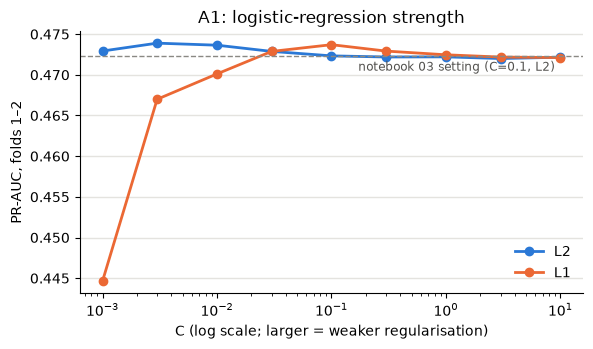

In [10]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for penalty, c in [('L2', '#2a78d6'), ('L1', '#eb6834')]:
    sub = a1[a1.setting.str.startswith(penalty)]
    Cs = sub.setting.str.split('C=').str[1].astype(float)
    ax.plot(Cs, sub['PR-AUC (folds 1–2)'], 'o-', color=c, lw=2, ms=6, label=penalty)
ax.set(xscale='log', xlabel='C (log scale; larger = weaker regularisation)', ylabel='PR-AUC, folds 1–2',
       title='A1: logistic-regression strength')
ax.axhline(base_ap, color='#8a8984', ls='--', lw=1)
ax.text(9, base_ap - 0.0006, 'notebook 03 setting (C=0.1, L2)', color='#52514e', va='top', ha='right', fontsize=8.5)
ax.legend(frameon=False)
ax.grid(axis='y', color='#e4e3df', lw=1)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Reading A1: flat.** Every L2 setting from C = 0.001 to 10 scores between 0.4720 and 0.4739, a spread at the noise level (0.002). The winner (C = 0.003) is ahead by 0.0016, within noise. L1 matches L2 only around C = 0.1 and collapses under strong regularisation, where it switches off useful features. **Notebook 03's untuned C = 0.1 was already as good as any choice.**

## 3 · A2 · Local-strictness radius and windows

The "area recent rates" (severe and fail rates of routine visits at any establishment nearby) were the clearest addition beyond an establishment's own record in notebook 03, but the 1 km radius and the 90 + 180-day windows were guesses. Each radius is computed once with all three windows; the window combinations are then tried as column subsets.

In [11]:
WINDOW_SETS = [(90,), (180,), (365,), (90, 180), (90, 365), (180, 365)]
keys = rows[['licenseno']].assign(t0=t0)
_, o_hist = history_tables(visits)
area_cols_base = [c for c in X_base.columns if c.startswith('area_')]
area_by_radius = {r: area_features(keys, o_hist, r, (90, 180, 365)) for r in [500, 1000, 2000]}

for r, A in area_by_radius.items():
    for ws in WINDOW_SETS:
        cols = [c for c in A.columns if int(c.rsplit('_', 1)[1][:-1]) in ws]
        X = pd.concat([X_base.drop(columns=area_cols_base), A[cols]], axis=1)
        record('A2', f'{r / 1000:g} km · {" + ".join(map(str, ws))} days', backtest(X, SELECTION_FOLDS, C=C_BEST, penalty=PEN))
a2 = pd.DataFrame([r for r in TRIALS if r['step'] == 'A2'])
best_a2 = a2.loc[a2['PR-AUC (folds 1–2)'].idxmax(), 'setting']
R_BEST = float(best_a2.split(' km')[0]) * 1000
W_BEST = tuple(int(w) for w in best_a2.split('· ')[1].replace(' days', '').split(' + '))
print(f'A2 winner: {best_a2}')
show('A2')

A2 winner: 1 km · 90 + 180 days


,setting,PR-AUC (folds 1–2),HR@50 (folds 1–2)
0,0.5 km · 90 days,0.4676,33.1%
1,0.5 km · 180 days,0.4673,33.0%
2,0.5 km · 365 days,0.4657,32.9%
3,0.5 km · 90 + 180 days,0.4691,33.2%
4,0.5 km · 90 + 365 days,0.4690,33.2%
5,0.5 km · 180 + 365 days,0.4674,33.0%
6,1 km · 90 days,0.4724,33.0%
7,1 km · 180 days,0.4713,32.9%
8,1 km · 365 days,0.4676,32.9%
9,1 km · 90 + 180 days,0.4739,32.9%


In [12]:
pivot = a2.assign(radius=a2.setting.str.split(' · ').str[0], windows=a2.setting.str.split(' · ').str[1]) \
          .pivot(index='windows', columns='radius', values='PR-AUC (folds 1–2)')
pivot.style.format('{:.4f}').background_gradient(cmap='Blues', axis=None)

radius,0.5 km,1 km,2 km
windows,,,
180 + 365 days,0.4674,0.4710,0.4628
180 days,0.4673,0.4713,0.4634
365 days,0.4657,0.4676,0.4606
90 + 180 days,0.4691,0.4739,0.4645
90 + 365 days,0.4690,0.4725,0.4640
90 days,0.4676,0.4724,0.4645


**Reading A2: the original guess was right, and the signal is genuinely local.** 1 km beats 0.5 km and 2 km for *every* window choice, and 1 km with 90 + 180 days (notebook 03's setting) is the best cell. **Radius matters more than window:** widening to 2 km costs about 0.009 PR-AUC (the local signal is diluted), shrinking to 0.5 km about 0.005 (too few nearby visits to estimate a rate). Within 1 km, the windows differ by at most 0.006, and a year-long window alone is the weakest. The pattern fits the reading in TECHNICAL.md §8: an area-level effect at about the scale of an inspector's territory, recent rather than long-run.

## 4 · A3 · Recency weight and "last N routine visits"

α sets how fast the recency-weighted fail and severe rates forget: a higher α puts more weight on the latest visit. N sets how many past routine visits the "last N" sums cover. These only change the history features, which are rebuilt for each combination (A1 and A2 winners kept).

In [13]:
A_best = area_by_radius[int(R_BEST)]
A_best = A_best[[c for c in A_best.columns if int(c.rsplit('_', 1)[1][:-1]) in W_BEST]]
X_by_a3 = {}
for alpha in [0.2, 0.35, 0.5, 0.7]:
    for n in [2, 3, 5]:
        v_h, o_h = history_tables(visits, alpha, n)
        hist, _ = history_features(keys, v_h, o_h)
        X = pd.concat([hist, X_base.drop(columns=list(hist.columns) + area_cols_base), A_best], axis=1)
        X_by_a3[(alpha, n)] = X
        record('A3', f'α={alpha:g} · N={n}', backtest(X, SELECTION_FOLDS, C=C_BEST, penalty=PEN))
a3 = pd.DataFrame([r for r in TRIALS if r['step'] == 'A3'])
best_a3 = a3.loc[a3['PR-AUC (folds 1–2)'].idxmax(), 'setting']
ALPHA_BEST, N_BEST = float(best_a3.split('α=')[1].split(' ')[0]), int(best_a3.split('N=')[1])
print(f'A3 winner: {best_a3}')
show('A3')

A3 winner: α=0.2 · N=2


,setting,PR-AUC (folds 1–2),HR@50 (folds 1–2)
0,α=0.2 · N=2,0.4772,32.9%
1,α=0.2 · N=3,0.4741,32.9%
2,α=0.2 · N=5,0.4758,33.0%
3,α=0.35 · N=2,0.4771,32.8%
4,α=0.35 · N=3,0.4740,32.9%
5,α=0.35 · N=5,0.4757,33.0%
6,α=0.5 · N=2,0.4771,32.9%
7,α=0.5 · N=3,0.4739,32.9%
8,α=0.5 · N=5,0.4757,33.0%
9,α=0.7 · N=2,0.4771,32.9%


**Reading A3: the recency weight is irrelevant; N barely matters.** α changes PR-AUC by at most 0.0001, because the model already sees the last and second-to-last routine visits and the lifetime rates, so the recency-weighted rates add nothing distinct. N = 2 edges out N = 3 (+0.003) and N = 5 (+0.001), slightly above the noise level.

## 5 · A4 · Drop the weak feature groups

Notebook 03's ablation suggested four groups add almost nothing. Starting from the A1–A3 winner, each group is removed in turn, then all four together. **Rule (fixed in advance): drop a group if removing it costs less than 0.002 PR-AUC.** A simpler model wins ties.

In [14]:
X_a3 = X_by_a3[(ALPHA_BEST, N_BEST)]
WEAK = {
    '311 nearby': [c for c in X_a3.columns if c.startswith(('food_complaints', 'rodent_reports'))],
    'owner': ['owner_known', 'owner_other_routine', 'owner_other_severe_rate'],
    'violation mix': [f'prev_{c}' for c in GROUP_COLS],
    'calendar & place': ['cat_FS', 'cat_FT', 'cat_RF', 'month_of_year', 'pandemic', 'lat', 'lon'],
}
ref_ap, _ = record('A4', 'keep all groups (A1–A3 winner)', backtest(X_a3, SELECTION_FOLDS, C=C_BEST, penalty=PEN))
drop_ok = []
for g, cols in WEAK.items():
    ap, _ = record('A4', f'drop {g}', backtest(X_a3.drop(columns=cols), SELECTION_FOLDS, C=C_BEST, penalty=PEN))
    if ap > ref_ap - NOISE:
        drop_ok.append(g)
all_cols = sum((WEAK[g] for g in drop_ok), [])
if len(drop_ok) > 1:
    ap_all, _ = record('A4', f'drop together: {", ".join(drop_ok)}', backtest(X_a3.drop(columns=all_cols), SELECTION_FOLDS, C=C_BEST, penalty=PEN))
    if ap_all <= ref_ap - NOISE:          # dropping them jointly costs too much: fall back to the single cheapest drop
        a4 = pd.DataFrame([r for r in TRIALS if r['step'] == 'A4' and r['setting'].startswith('drop ') and 'together' not in r['setting']])
        drop_ok = [a4.loc[a4['PR-AUC (folds 1–2)'].idxmax(), 'setting'].replace('drop ', '')]
DROPPED = drop_ok
FEATURES_FINAL = [c for c in X_a3.columns if c not in sum((WEAK[g] for g in DROPPED), [])]
print(f'groups dropped: {DROPPED or "none"} → {len(FEATURES_FINAL)} features (from {X_a3.shape[1]})')
show('A4')

groups dropped: ['311 nearby', 'owner', 'violation mix', 'calendar & place'] → 33 features (from 55)


,setting,PR-AUC (folds 1–2),HR@50 (folds 1–2)
0,keep all groups (A1–A3 winner),0.4772,32.9%
1,drop 311 nearby,0.4782,32.9%
2,drop owner,0.4775,33.0%
3,drop violation mix,0.4762,32.9%
4,drop calendar & place,0.4758,33.0%
5,"drop together: 311 nearby, owner, violation mix, calendar & place",0.4761,32.9%


## 6 · The tuned model, and the exit verdict

**Tuned configuration:** the A1–A4 winners, printed below. It now runs through the full backtest for the first time. **2024 is the clean year:** no setting was chosen on it.

In [15]:
TUNED = dict(C=C_BEST, penalty=PEN, area_radius_m=R_BEST, area_windows=W_BEST, ewm_alpha=ALPHA_BEST, last_n=N_BEST,
             dropped_groups=DROPPED, n_features=len(FEATURES_FINAL))
X_final = X_a3[FEATURES_FINAL]
oof_tuned = backtest(X_final, ALL_FOLDS, C=C_BEST, penalty=PEN)
ev['tuned'] = oof_tuned.loc[ev.index].to_numpy()
pd.Series({k: str(v) for k, v in TUNED.items()}).to_frame('tuned value').join(
    pd.Series({'C': '0.1', 'penalty': 'l2', 'area_radius_m': '1000', 'area_windows': '(90, 180)', 'ewm_alpha': '0.5',
               'last_n': '3', 'dropped_groups': 'none', 'n_features': str(X_base.shape[1])}).to_frame('notebook 03'))

,tuned value,notebook 03
C,0.003,0.1
penalty,l2,l2
area_radius_m,1000.0,1000
area_windows,"(90, 180)","(90, 180)"
ewm_alpha,0.2,0.5
last_n,2,3
dropped_groups,"['311 nearby', 'owner', 'violation mix', 'cale...",none
n_features,33,55


In [16]:
def compare(e, label):
    pm = {k: per_month(e, k) for k in ['actual', 'rule1', 'E1', 'tuned', 'oracle']}
    out = {}
    for k, name in [('actual', 'Current practice'), ('rule1', 'Rule 1 · previous inspection'),
                    ('E1', 'E1 · logistic regression (notebook 03)'), ('tuned', 'Tuned logistic regression (03b)'),
                    ('oracle', 'Oracle')]:
        hr = hit_rate(pm[k])
        lo, hi = bootstrap_diff(pm[k], pm['rule1'])
        out[name] = {f'HR@50 ({label})': hr, 'vs Rule 1 (per 100)': 100 * (hr - hit_rate(pm['rule1'])),
                     'vs Rule 1 95% CI': f'[{100 * lo:+.1f}, {100 * hi:+.1f}]' if k not in ('rule1',) else '—',
                     'days earlier': days_earlier(e, k), 'PR-AUC': average_precision_score(e.hit, e[k])}
    return pd.DataFrame(out).T

clean = compare(ev[ev.visit_ts.dt.year == 2024], '2024, clean')
clean.style.format({'HR@50 (2024, clean)': '{:.1%}', 'vs Rule 1 (per 100)': '{:+.1f}', 'days earlier': '{:.1f}', 'PR-AUC': '{:.3f}'})

,"HR@50 (2024, clean)",vs Rule 1 (per 100),vs Rule 1 95% CI,days earlier,PR-AUC
Current practice,23.8%,-8.5,"[-10.6, -6.6]",0.0,0.245
Rule 1 · previous inspection,32.4%,+0.0,—,3.4,0.358
E1 · logistic regression (notebook 03),35.0%,+2.6,"[+1.8, +3.5]",4.9,0.430
Tuned logistic regression (03b),34.8%,+2.4,"[+1.5, +3.5]",4.9,0.423
Oracle,46.5%,+14.1,"[+12.1, +16.2]",10.9,1.000


In [17]:
pooled = compare(ev, '2022–24 pooled')
print('Pooled 2022–24, for continuity with notebook 03 (2022–23 chose the settings, so this is slightly flattered):')
pooled.style.format({'HR@50 (2022–24 pooled)': '{:.1%}', 'vs Rule 1 (per 100)': '{:+.1f}', 'days earlier': '{:.1f}', 'PR-AUC': '{:.3f}'})

Pooled 2022–24, for continuity with notebook 03 (2022–23 chose the settings, so this is slightly flattered):


,HR@50 (2022–24 pooled),vs Rule 1 (per 100),vs Rule 1 95% CI,days earlier,PR-AUC
Current practice,21.5%,-9.5,"[-10.5, -8.6]",0.0,0.225
Rule 1 · previous inspection,31.0%,+0.0,—,4.1,0.350
E1 · logistic regression (notebook 03),33.8%,+2.9,"[+2.3, +3.4]",5.8,0.456
Tuned logistic regression (03b),33.5%,+2.6,"[+2.0, +3.1]",5.8,0.454
Oracle,43.2%,+12.2,"[+11.1, +13.3]",11.4,1.000


In [18]:
row = clean.loc['Tuned logistic regression (03b)']
gain, lo = row['vs Rule 1 (per 100)'], float(row['vs Rule 1 95% CI'].strip('[]').split(',')[0])
e1_gain = clean.loc['E1 · logistic regression (notebook 03)', 'vs Rule 1 (per 100)']
pm24 = {k: per_month(ev[ev.visit_ts.dt.year == 2024], k) for k in ['tuned', 'E1']}
d_lo, d_hi = bootstrap_diff(pm24['tuned'], pm24['E1'])
print(f'2024 (clean): tuned − Rule 1 = {gain:+.1f} per 100 visits, 95% CI {row["vs Rule 1 95% CI"]}')
print(f'              tuning itself: tuned − notebook-03 model = {gain - e1_gain:+.1f}, 95% CI [{100 * d_lo:+.1f}, {100 * d_hi:+.1f}]')
print(f'EXIT CRITERION (≥ +3.0 on 2024 and CI excluding zero): {"MET" if gain >= 3 and lo > 0 else "NOT MET"}')

2024 (clean): tuned − Rule 1 = +2.4 per 100 visits, 95% CI [+1.5, +3.5]
              tuning itself: tuned − notebook-03 model = -0.2, 95% CI [-0.6, +0.2]
EXIT CRITERION (≥ +3.0 on 2024 and CI excluding zero): NOT MET


## 7 · Findings and decisions (tuning round)

**Results**

| | Notebook 03 model | Tuned (03b) |
|---|---|---|
| Settings | C = 0.1 · 1 km, 90 + 180 d · α = 0.5, N = 3 · 55 features | C = 0.003 · 1 km, 90 + 180 d · α = 0.2, N = 2 · **33 features** (311, owner, violation mix, calendar dropped) |
| Selection score, folds 1–2 (PR-AUC) | 0.4723 | 0.4761 |
| **2024, clean: first-half hit rate** | **35.0%** | **34.8%** |
| 2024 vs Rule 1, per 100 visits | +2.6 [+1.8, +3.5] | +2.4 [+1.5, +3.5] |
| Pooled 2022–24 vs Rule 1 (flattered for 03b) | +2.9 [+2.3, +3.4] | +2.6 [+2.0, +3.1] |

1. **Tuning did not improve the model.** The small gains on the selection years (+0.004 PR-AUC) did not carry over to the clean year: −0.2 hits per 100 visits against notebook 03's model, 95% CI −0.6 to +0.2. Every setting was already at or near its best.
2. **This confirms notebook 03's conclusion from a second direction.** Neither a more complex algorithm (notebook 03) nor better-tuned settings (here) moves the result. The ceiling is the information in the data.
3. **The local-strictness signal is real and local:** best at about 1 km and the last 3–6 months, clearly weaker when widened to 2 km. It is not a fragile artefact of the setting.
4. **A simpler model is just as good.** Dropping the 311, owner, violation-mix and calendar groups (55 → 33 features) costs nothing measurable. A smaller model is easier to explain, audit and maintain.
5. **Exit criterion: NOT MET** on the clean year (+2.4, CI +1.5 to +3.5, vs the +3 bar). For transparency: notebook 03's model on 2024 alone is +2.6, also below the bar.

**Decisions**
- ✅ **Decided 2026-11-11: model (b) carries forward as the Phase 1 model.** The simplified 33-feature logistic regression (C = 0.003, L2; local rates within 1 km over 90 + 180 days; last N = 2; the 311, owner, violation-mix and calendar groups dropped). It replaces the notebook-03 model (a) by the project rule "simplest model within noise of the best": equal accuracy on the clean year with 22 fewer inputs. It is the baseline Phase 2 must improve on, and it is the model used in §8.
- **Phase 2 go / no-go** (PLAN.md, step 4) is still open. The exit bar is still narrowly missed, and tuning has been ruled out as a lever. Recommendation: **go**. The remaining misses need information that the structured data does not contain.

## 8 · Two-week replay: how much do the results rely on "conditions are stable within the month"?

**Why this check.** Outcomes are known only for visits that happened, so every evaluation so far re-orders each month's *actual* visits and assumes a kitchen would show the same condition if visited earlier or later in that month. A visit can move by up to about four weeks. If many Priority problems appear or disappear within weeks, that assumption flatters the gains (TECHNICAL.md §4).

**What changes.** The same comparison (current practice, Rule 1, **model (b)**, oracle), but each month is split into two blocks (days 1–15 and 16–end), and visits are re-ranked **within each block**. No visit moves more than two weeks, and on average about half as far. HR@50 becomes "the hit rate in the first half of each two-week block". **What stays fixed:** the scores are still computed as of the start of the month, so the model gets no fresher information. That makes the check conservative.

**How to read it.** If model (b)'s gain over Rule 1, and the share of the headroom it captures, are about the same on two-week blocks as on months, the conclusions don't depend on conditions staying stable for a whole month.

In [19]:
ev['period_month'] = ev['month']
ev['period_2wk'] = ev['month'] + np.where(ev.visit_ts.dt.day <= 15, '·a', '·b')
blocks = ev.groupby('period_2wk').size()
print(f'two-week blocks: {len(blocks)} · visits per block: median {blocks.median():.0f}, min {blocks.min()}')

METHODS = [('actual', 'Current practice'), ('rule1', 'Rule 1 · previous inspection'),
           ('tuned', 'Model (b) · simplified logistic regression'), ('oracle', 'Oracle')]

def replay(e, period, label):
    e = e.assign(month=e[period])                     # the metric helpers group by "month"
    pm = {k: per_month(e, k) for k, _ in METHODS}
    base, orc, r1 = hit_rate(pm['actual']), hit_rate(pm['oracle']), hit_rate(pm['rule1'])
    out = {}
    for k, name in METHODS:
        hr = hit_rate(pm[k])
        lo, hi = bootstrap_diff(pm[k], pm['rule1'])
        out[name] = {'period': label, 'HR@50': hr, 'vs Rule 1 (per 100)': 100 * (hr - r1),
                     'vs Rule 1 95% CI': '—' if k == 'rule1' else f'[{100 * lo:+.1f}, {100 * hi:+.1f}]',
                     'headroom captured': (hr - base) / (orc - base), 'days earlier': days_earlier(e, k)}
    return pd.DataFrame(out).T

rows_out = []
for years, ylab in [([2024], '2024 (clean)'), (ALL_FOLDS, '2022–24 pooled')]:
    e = ev[ev.visit_ts.dt.year.isin(years)]
    for period, plab in [('period_month', 'monthly'), ('period_2wk', 'two-week')]:
        rows_out.append(replay(e, period, f'{ylab} · {plab}'))
replay_table = pd.concat(rows_out)
replay_table.style.format({'HR@50': '{:.1%}', 'vs Rule 1 (per 100)': '{:+.1f}', 'headroom captured': '{:.0%}', 'days earlier': '{:.1f}'})

two-week blocks: 72 · visits per block: median 238, min 118


,period,HR@50,vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier
Current practice,2024 (clean) · monthly,23.8%,-8.5,"[-10.6, -6.6]",0%,0.0
Rule 1 · previous inspection,2024 (clean) · monthly,32.4%,+0.0,—,38%,3.4
Model (b) · simplified logistic regression,2024 (clean) · monthly,34.8%,+2.4,"[+1.5, +3.5]",48%,4.9
Oracle,2024 (clean) · monthly,46.5%,+14.1,"[+12.1, +16.2]",100%,10.9
Current practice,2024 (clean) · two-week,23.3%,-9.1,"[-10.9, -7.4]",0%,0.0
Rule 1 · previous inspection,2024 (clean) · two-week,32.4%,+0.0,—,39%,1.7
Model (b) · simplified logistic regression,2024 (clean) · two-week,34.9%,+2.5,"[+1.4, +3.6]",50%,2.4
Oracle,2024 (clean) · two-week,46.5%,+14.1,"[+12.3, +15.9]",100%,5.2
Current practice,2022–24 pooled · monthly,21.5%,-9.5,"[-10.5, -8.6]",0%,0.0
Rule 1 · previous inspection,2022–24 pooled · monthly,31.0%,+0.0,—,44%,4.1


In [20]:
summary = replay_table[replay_table.index.str.startswith('Model (b)')].set_index('period')[
    ['vs Rule 1 (per 100)', 'vs Rule 1 95% CI', 'headroom captured', 'days earlier']]
r1_head = replay_table[replay_table.index.str.startswith('Rule 1')].set_index('period')['headroom captured']
summary.insert(3, 'Rule 1 headroom captured', r1_head)
summary.style.format({'vs Rule 1 (per 100)': '{:+.1f}', 'headroom captured': '{:.0%}', 'Rule 1 headroom captured': '{:.0%}', 'days earlier': '{:.1f}'})

,vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,Rule 1 headroom captured,days earlier
period,,,,,
2024 (clean) · monthly,+2.4,"[+1.5, +3.5]",48%,38%,4.9
2024 (clean) · two-week,+2.5,"[+1.4, +3.6]",50%,39%,2.4
2022–24 pooled · monthly,+2.6,"[+2.0, +3.1]",56%,44%,5.8
2022–24 pooled · two-week,+2.5,"[+1.9, +3.0]",55%,43%,2.8


### Findings (two-week replay)

| Model (b) | vs Rule 1, per 100 visits | Headroom captured (Rule 1) | Days earlier |
|---|---|---|---|
| 2024 · monthly | +2.4 [+1.5, +3.5] | 48% (38%) | 4.9 |
| **2024 · two-week** | **+2.5 [+1.4, +3.6]** | **50% (39%)** | 2.4 |
| 2022–24 · monthly | +2.6 [+2.0, +3.1] | 56% (44%) | 5.8 |
| **2022–24 · two-week** | **+2.5 [+1.9, +3.0]** | **55% (43%)** | 2.8 |

1. **The ranking advantage does not depend on month-long stability.** When no visit may move more than two weeks, model (b) still finds +2.5 more hits per 100 early visits than Rule 1, and captures the same share of the headroom (50% vs 48% in 2024). Both rules hold their ground too. If many Priority problems appeared or vanished within weeks, the monthly replay would have flattered the gains, and the two-week numbers would be noticeably lower. They are not.
2. **"Days earlier" halves, by construction.** With visits confined to two-week blocks, a hit can only move about half as far (2.4 vs 4.9 days in 2024). This is a property of the planning period, not of the model: the *per-visit* lift is the same, while the *time* gained scales with how far a list can move visits.
3. **What it does not prove.** Stability over ≤ 2 weeks is still assumed; only a live pilot removes the assumption entirely. The check bounds the concern rather than eliminating it.
4. **Practical implication.** A twice-monthly list would deliver the same per-visit lift with fresher inputs available. The scores here were still computed at the start of the month, so the comparison is conservative.

## 9 · Experiment log

In [21]:
log = pd.DataFrame(TRIALS).rename(columns={'setting': 'experiment', 'PR-AUC (folds 1–2)': 'PR-AUC', 'HR@50 (folds 1–2)': 'HR@50'})
log['note'] = 'selection score on folds 1–2 (2022–23); step ' + log.pop('step')
final = clean.reset_index(names='experiment').rename(columns={'HR@50 (2024, clean)': 'HR@50'})
final = final[final.experiment.str.contains('Tuned|E1')]
final['note'] = 'final check on 2024 (clean)'
final['params'] = final.experiment.map({'Tuned logistic regression (03b)': str(TUNED)}).fillna('')
replay_log = replay_table.reset_index().rename(columns={'index': 'experiment'})
replay_log = replay_log.assign(experiment=lambda d: d.experiment + ' · ' + d.period, note='two-week replay (§8); HR@50 = first half of each block or month')
log = pd.concat([log, final, replay_log[['experiment', 'HR@50', 'vs Rule 1 (per 100)', 'vs Rule 1 95% CI', 'days earlier', 'note']]], ignore_index=True)
log.insert(0, 'date', date.today().isoformat())
log.insert(1, 'notebook', '03b_tuning_round')
path = config.RESULTS / 'experiments.csv'
previous = pd.read_csv(path)
previous = previous[previous.notebook != '03b_tuning_round']       # re-running replaces this notebook's rows
pd.concat([previous, log], ignore_index=True).to_csv(path, index=False)
print(f'wrote {len(log)} rows for this notebook to {path.relative_to(config.ROOT)}')
pd.DataFrame(CHECKS)

wrote 73 rows for this notebook to results/experiments.csv


,risk,check,result,detail
0,R13,keyword groups cover ≥95% of violations in bot...,pass,"2020+: 96.0%, before 2020: 99.7%"
1,R14,no test-period rows built,pass,"27,457 rows"
2,R23,notebook-03 logistic regression reproduced exa...,pass,HR@50 0.3383 here vs 0.3383 in notebook 03
